# 02 - Exploratory data analysis and feature selection

**Purpose:** understand missingness, skew, and main drivers of fraud, then make and record explicit feature decisions for the baseline model.

**Scope:** all analysis uses the training period only (days 0-119), so no feature decision is influenced by the validation or test periods

In [1]:
# Imports
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

In [2]:
# Load the data
tx = pd.read_csv("../data/train_transaction.csv")
idn = pd.read_csv("../data/train_identity.csv")


In [3]:
# Set up dataframe
df = tx.merge(idn, on="TransactionID", how="left")

df['day'] = df['TransactionDT'] / (60*60*24)
df['has_identity'] = df['TransactionID'].isin(idn['TransactionID']).astype(int)

# Keep only the training period
train = df[df['day'] < 120].copy()
del tx, idn, df # free up some memory

In [4]:
# What kind of columns do we have?
# Numeric columns can go straight into a baseline; object columns require encoding first

print(train.dtypes.value_counts())

float64    400
str         31
int64        5
Name: count, dtype: int64


Columns with no missing values: 65
Columns with more than 50% missing values: 229
Columns with more than 90% missing values: 12


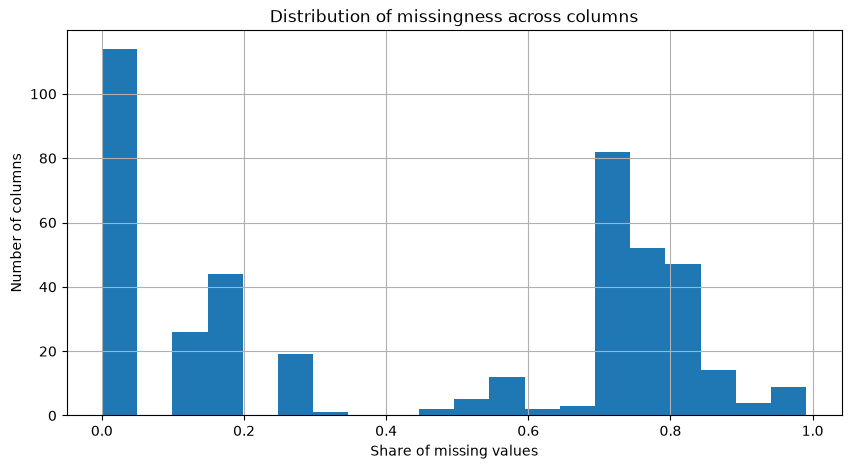

In [5]:
# Share of missing values in each column
missing = train.isna().mean().sort_values(ascending=False)

print("Columns with no missing values:", (missing==0).sum())
print("Columns with more than 50% missing values:", (missing>0.5).sum())
print("Columns with more than 90% missing values:", (missing>0.9).sum())

missing.hist(bins=20, figsize=(10,5))
plt.title("Distribution of missingness across columns")
plt.xlabel("Share of missing values")
plt.ylabel("Number of columns")
plt.show()

There are 12 columns that are heavily missing (>90%) and a substantial number around 80%. Most of the data set has missing values. This is expected as identity colums only exist for about a quarter of transactions. Missing values need a deliberate treatment, because in fraud data 'missing' values can itself be a signal (see 01 notebook 2.1% vs 7.9% fraud rates).

In [6]:
# Checking for skewness in the transaction amount column, which is a common feature in fraud detection datasets
amt = train['TransactionAmt']
print(amt.describe())
print("Skewness:", round(amt.skew(), 2), "| after log1p:", round(np.log1p(amt).skew(),2))

count    410601.000000
mean        134.534834
std         237.944533
min           0.251000
25%          42.950000
50%          68.950000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64
Skewness: 17.72 | after log1p: 0.5



Median amount by class (0 = genuine, 1 = fraud):
isFraud
0    68.950
1    75.498
Name: TransactionAmt, dtype: float64


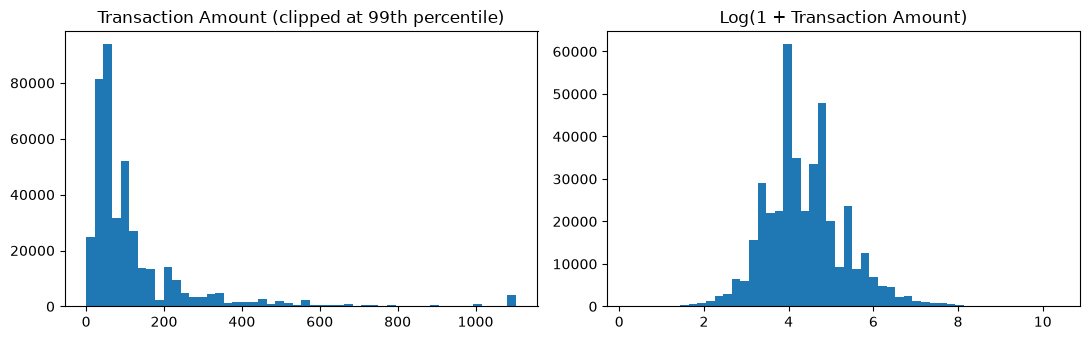

In [7]:
# Median is more informative than the mean when the distribution is skewed
print("\nMedian amount by class (0 = genuine, 1 = fraud):")
print(train.groupby('isFraud')['TransactionAmt'].median())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
# Raw chart is clipped at the 99th percentile, otherwise a few huge values squash the whole chart
axes[0].hist(amt.clip(upper=amt.quantile(0.99)), bins=50)
axes[0].set_title("Transaction Amount (clipped at 99th percentile)")
axes[1].hist(np.log1p(amt), bins=50)
axes[1].set_title("Log(1 + Transaction Amount)")
plt.tight_layout()
plt.show()

In [8]:
# Fraud rate by amount band (deciles). If amount matters, the rate should trend across bands.
bands = pd.qcut(train['TransactionAmt'], q=10, duplicates='drop')
print((train.groupby(bands, observed=True)['isFraud'].agg(['count', 'mean']) * [1, 100]).round(2))

                    count  mean
TransactionAmt                 
(0.25, 25.95]       42164  5.50
(25.95, 35.95]      42309  3.29
(35.95, 49.0]       44386  3.24
(49.0, 57.95]       42766  1.91
(57.95, 68.95]      33923  2.87
(68.95, 100.0]      52500  3.47
(100.0, 117.0]      47277  1.95
(117.0, 160.0]      23180  4.38
(160.0, 280.0]      42948  4.02
(280.0, 31937.391]  39148  5.09


Transaction amounts are right-skewed and skewness falls from 17.72 to 0.5 after a log transformation.
Skewed inputs can distort a linear model (such as logistic regression), so I will add a log-transformation to the transaction amount for the baseline model. Tree-based models are not affected by monotonic transformations, so the comparison does not need it. Median amount for genuine vs fraud: 68.95 vs 75.50, but the median hides a U-shaped pattern where fraud rate is about 5% in the lowest amount bands, falls to 2-3% in the middle, and rises to 4-5% in the highest bands. Amount is therefore more informative than the median suggests, but its effect is non-linear. I will add a squared log-amount term in the baseline model so that the linear logistic regression can capture it, and tree-based models can learn it directly.

In [9]:
# Fraud rate by category. dropna=False shows 'missing' as its own category, which is where signal often hides in this dataset.
# min_count removes tiny categories whose rates are noisy.
def fraud_by(col, min_count=1000, top=10):
    t = train.groupby(col, dropna=False)['isFraud'].agg(['count', 'mean'])
    t = t[t['count'] >= min_count].sort_values('mean', ascending=False).head(top)
    t['mean'] = (t['mean'] * 100).round(2)
    t.columns = ['transactions', 'fraud_rate_%']
    return t

for col in ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'DeviceType']:
    print(col)
    print(fraud_by(col))
    print()

ProductCD
           transactions  fraud_rate_%
ProductCD                            
C                 49665         11.15
S                  7171          6.04
H                 28048          4.52
R                 30037          3.48
W                295680          2.07

card4
                  transactions  fraud_rate_%
card4                                       
discover                  4745          6.58
mastercard              129895          3.57
visa                    268406          3.45
american express          6726          2.81

card6
        transactions  fraud_rate_%
card6                             
credit        108866          6.57
debit         300865          2.41

P_emaildomain
               transactions  fraud_rate_%
P_emaildomain                            
outlook.com            3520          8.95
hotmail.com           32587          5.31
gmail.com            158056          4.40
live.com               2182          3.57
icloud.com             4292      

In [10]:
# Skew across numeric columns.
exclude = ['isFraud', 'TransactionID', 'TransactionDT', 'day']
num_cols = [c for c in train.select_dtypes('number').columns if c not in exclude]

skew = train[num_cols].skew().abs().sort_values(ascending=False)
print(f"Numeric columns with |skew| > 2: {(skew > 2).sum()} of {len(num_cols)}")
print(skew.head(10))

Numeric columns with |skew| > 2: 336 of 401
V305    369.947294
V311    318.663330
V129    250.942026
V309    236.552072
V319    209.874834
V206    198.416624
V321    187.136918
V269    169.920338
V266    168.436352
V214    164.222146
dtype: float64


In [11]:
# Quick screen: how weel does each numeric column predict fraud on its own? AUC is rank-based, so skew doesn't affect it. 0.5 = no signal
# This is a guide to where signal might be, it cannot see interactions between columns.
y = train['isFraud']
scores = {}
for col in num_cols:
    x = train[col]
    if x.nunique() < 2: # constant or all-missing columns carry no information
        continue
    auc = roc_auc_score(y, x.fillna(x.median()))
    scores[col] = max(auc, 1 - auc) # AUC is symmetric, so we only care about the distance from 0.5

screen = pd.Series(scores).sort_values(ascending=False)
print(screen.head(15))

C4              0.683882
C8              0.678394
C10             0.673506
D5              0.660461
V303            0.657104
C12             0.656179
V304            0.654788
V302            0.651941
has_identity    0.648535
V283            0.642589
C7              0.642584
V218            0.642350
V264            0.641559
C5              0.641231
V219            0.638213
dtype: float64


In [17]:
# Feature Decisions
# Drop columns that are constant in train (no information)
constant = [c for c in num_cols if train[c].nunique() < 2]

# Drop columns that are more than 90% missing, but first check that we aren't throwing away any signal.
missing_90 = [c for c in num_cols if missing[c] > 0.9 and c not in constant]
print("Columns >90% missing:", len(missing_90))
print("Best single_column score among them:", round(screen.reindex(missing_90).max(), 3))

# Drop columns that are ID-like
id_like = ['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2']

# Add a log-transformed amount, and keep the has_identity flag
train['log_amt'] = np.log1p(train['TransactionAmt'])
train['log_amt_sq'] = train['log_amt'] ** 2     # lets the linear baseline represent the U-shape seen in the deciles

numeric_features = [c for c in num_cols if c not in constant + missing_90 + id_like] + ['log_amt', 'log_amt_sq']
print("Numeric features:", len(numeric_features))

Columns >90% missing: 10
Best single_column score among them: 0.516
Numeric features: 386


In [18]:
# Categorical: string columns with <= 20 distinct values (missing becomes its own category)
obj_cols = train.select_dtypes('object').columns.tolist()
cat_cols = [c for c in obj_cols if train[c].nunique() <= 20]
dropped_cat = [c for c in obj_cols if c not in cat_cols]

print("Numeric features:", len(numeric_features))
print("Categorical features kept:", len(cat_cols), cat_cols)
print("Categorical dropped (>20 values):", dropped_cat)

/var/folders/h4/k_f852dx38gdfjcq9cxdlv4c0000gn/T/ipykernel_19893/697504582.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = train.select_dtypes('object').columns.tolist()


Numeric features: 386
Categorical features kept: 25 ['ProductCD', 'card4', 'card6', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType']
Categorical dropped (>20 values): ['P_emaildomain', 'R_emaildomain', 'id_30', 'id_31', 'id_33', 'DeviceInfo']


In [19]:
# Save the lists so the baseline and comparison notebooks use identical inputs
with open("../reports/features.json", "w") as f:
    json.dump({"numeric": numeric_features, "categorical": cat_cols}, f, indent=2)

## What I found

- **Missingness:** 241 of 306 columns are more than 50% missing and 12 more than 90%. Most of columns have gaps, largely driven by identity data, which exists for only 24.4% of transactions.
- **Identity data is informative:** fraud rate is 7.9% where identity exists and 2.1% where it doesn't, so I keep a has_identity flag instead of treating missing as random noise.
- **Amount is non-linear:** median amount is higher in fraud than genuine (75.50 vs 68.95), but fraud rate by decile is U-shaped. Raw skewness is 17.72 falling to 0.5 after a log transformation.
- **Skew:** 336 of 403 numeric colums have |skew| > 2, so tree-based models and rank-based screening are better suited than linear fits.
- **Categorical drivers:** In ProductCD, C has the highest fraud rate at 11.15% across 50k transactions, against 3.4% for R.
- **No single dominant feature:** the top 15 numeric columns score 0.63-0.68 in the single column screen (0.5 = random), so each is a modest signal alone. Signal is spread across many weak features, so a mulitvariate model should help

## Rules and Corners I cut
I deliberately used blunt, rule-based cuts to keep the project focused on the decision and recommendation, rather than on exhaustive feature engineering.
| Corner cut | Why I made it | What it may cost | With more time |
|---|---|---|---|
| Dropped constant columns and columns >90% missing | Fast, reproducible, removes most sparse engineering columns | May discard weak signal. Best single-column score among them was 0.516 vs 0.63-0.68 for the top features so little is lost | Keep missing-indicators for these columns, or test the threshold |
| Dropped text columns with >20 categories | They need grouping or frequency encoding, which is slow | Likely drops useful signal such as email domain or device info | GRoup rare categories, or use target/frequency encoding fitted on train only |
| Used one-hot encoding with missing as its own category | Simple, works for both models | Wide matrices if cardinality creeps up | Compare against native categorical handling in the tree model |
| Screened columns one at a time (single-column AUC) | Quick guide to where signal sits | Blind to interactions | Use model-based importance on the comparison |
| Did not test whether the U-shape in amount survives within each product type | Time | The shape could partly reflect product mix | Fraud rate by amount band within each 'ProductCD' |
| Median imputation for numeric columns in the baseline | Standard, robust to skew | Hides missingness, partly offset by 'has_identity' | Add missing-indicator columns |

## Decisions
1. Drop constant columns and columns more than 90% missing. The best score among those dropped was 0.516, so little signal is lost.
2. Add 'log_amt' to counter skew in the linear baseline. And 'log_amt_sq' so the linear baseline can represent the U-shaped amount effect.
3. Keep 'has_identity' as an explicit missingness flag.
4. Apply the rules above to build a single feature list, saved to 'reports/features.json'.
5. Give the baseline and comparison identical inputs, so any improvement comes from the model and not extra information.

## Limitations
- Feature selection intentionally coarse. The comparison will likely improve with richer categorical handling, so its result here is a conservative esimate.
- Single-column screening can't see interactions, so a weak column may still help in combination.
- Univeriate scores come from the training period; relationships may drift over time.
- Several columns are anonymised, so I can rank them but not interperet them.